## Интеллектуальный анализ данных – весна 2026
## Домашнее задание 4: kNN. Линейные модели. Работа с признаками

### Задание 1:  Визуализация решающих поверхностей в kNN.

В этом задании мы изобразим решающую поверхность для классификатора kNN, чтобы наглядно увидеть, как классификатор принимает решения для новых объектов. Для простоты будем работать с усеченным датасетом `Palmer Penguins`, содержащим информацию о характеристиках трех видов пингвинов: `Adelie`, `Chinstrap` и `Gentoo`:



*   Species — вид пингвина (целевая переменная).
*   Island — остров, на котором была сделана запись.
*   Clutch Completion — завершенность кладки яиц.
*   Date Egg — закодированная дата откладки яиц (число дней от самой ранней даты в данных).
*   Culmen Length (mm) — длина клюва.
*   Culmen Depth (mm) — глубина клюва.
*   Flipper Length (mm) — длина ласт.
*   Body Mass (g) — масса тела в граммах.
*   Sex — пол особи.
*   Delta 15 N (o/oo) и Delta 13 C (o/oo) — изотопные значения, характеризующие пищевые предпочтения.

Описание полного набора данных и дополнительную информацию о проекте можно найти [здесь](https://allisonhorst.github.io/palmerpenguins/index.html) и [здесь](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data?resource=download).

![Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/reference/figures/lter_penguins.png)



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv('penguins_data.csv')
data.head(10)

,Species,Island,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo)
0,Chinstrap,Dream,Yes,382,50.9,19.1,196.0,3550.0,MALE,10.02372,-24.86594
1,Chinstrap,Dream,Yes,741,45.2,17.8,198.0,3950.0,FEMALE,8.88942,-24.49433
2,Gentoo,Biscoe,Yes,744,46.5,13.5,210.0,4550.0,FEMALE,7.99530,-25.32829
3,Chinstrap,Dream,Yes,10,45.2,16.6,191.0,3250.0,FEMALE,9.62357,-24.78984
4,Gentoo,Biscoe,Yes,13,48.4,14.4,203.0,4625.0,FEMALE,8.16582,-26.13971
5,Gentoo,Biscoe,Yes,22,48.1,15.1,209.0,5500.0,MALE,8.45738,-26.22664
6,Gentoo,Biscoe,Yes,13,51.1,16.5,225.0,5250.0,MALE,8.20660,-26.36863
7,Gentoo,Biscoe,No,392,42.7,13.7,208.0,3950.0,FEMALE,8.14567,-26.59467
8,Adelie,Biscoe,Yes,14,39.6,20.7,191.0,3900.0,FEMALE,8.80967,-26.78958
9,Gentoo,Biscoe,Yes,735,46.1,13.2,211.0,4500.0,FEMALE,7.99300,-25.51390


**Задача 1.1 (0.5 балла)** Есть ли в наборе данных пропущенные значения? Если да, то удалите их. Есть ли в наборе данных категориальные признаки? Если да, то закодируйте их самым оптимальным способом. Аргументируйте свой выбор.

In [ ]:
data.isnull().sum()

,0
Species,0
Island,0
Clutch Completion,0
Date Egg,0
Culmen Length (mm),2
Culmen Depth (mm),2
Flipper Length (mm),2
Body Mass (g),2
Sex,10
Delta 15 N (o/oo),14


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Species              344 non-null    object 
 1   Island               344 non-null    object 
 2   Clutch Completion    344 non-null    object 
 3   Date Egg             344 non-null    int64  
 4   Culmen Length (mm)   342 non-null    float64
 5   Culmen Depth (mm)    342 non-null    float64
 6   Flipper Length (mm)  342 non-null    float64
 7   Body Mass (g)        342 non-null    float64
 8   Sex                  334 non-null    object 
 9   Delta 15 N (o/oo)    330 non-null    float64
 10  Delta 13 C (o/oo)    331 non-null    float64
dtypes: float64(6), int64(1), object(4)
memory usage: 29.7+ KB


Итак, в датасете есть пропущенные значения и категориальные признаки. Замечаем, что в наборе данных есть '.' в столбце sex, что портит данные. Удалим данную строку, а также строки с пропущенными значениями. В наборе данных есть 3 категориальных признака: Island,	Clutch Completion, Sex. Так как последние 2 относятся к бинарным (для Clutch Completion: Yes/No, для Sex: Male/Female), поэтому положим бинарное кодирование: 0 для 'No' и 'Female', 1 для 'Yes', 'Male'. В случае Island, применим One-hot encoding (метод с семинара), тк тут 3 признака: Island_Biscoe, Island_Dream, Island_Torgersen


In [ ]:
data_without = data[data['Sex'].isin(['MALE', 'FEMALE'])] # оставим строки, где в столбце sex только значения 'MALE' / 'FEMALE
data_clear = data_without.dropna().copy()
display(data_clear.isnull().sum()) # проверим, что пропусков больше нет

data_clear['Sex_Code'] = (data_clear['Sex'] == 'MALE').astype(int) # 1 - если MALE, иначе - 0
data_clear['Clutch_Code'] = (data_clear['Clutch Completion'] == 'Yes').astype(int) # 1 - если Yes, иначе - 0
island_dum = pd.get_dummies(data_clear['Island']).astype(int) # создаем столбцы с помощью one-hot encoding
data_without_categorical = data_clear.drop(['Island', 'Sex', 'Clutch Completion'], axis=1) # удаляем столбцы с категориальными данными
data_clear = pd.concat([data_without_categorical, island_dum], axis=1) # склеиваем в единый датафрейм

data_clear.head(10)

,0
Species,0
Island,0
Clutch Completion,0
Date Egg,0
Culmen Length (mm),0
Culmen Depth (mm),0
Flipper Length (mm),0
Body Mass (g),0
Sex,0
Delta 15 N (o/oo),0


,Species,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Delta 15 N (o/oo),Delta 13 C (o/oo),Sex_Code,Clutch_Code,Biscoe,Dream,Torgersen
0,Chinstrap,382,50.9,19.1,196.0,3550.0,10.02372,-24.86594,1,1,0,1,0
1,Chinstrap,741,45.2,17.8,198.0,3950.0,8.88942,-24.49433,0,1,0,1,0
2,Gentoo,744,46.5,13.5,210.0,4550.0,7.99530,-25.32829,0,1,1,0,0
3,Chinstrap,10,45.2,16.6,191.0,3250.0,9.62357,-24.78984,0,1,0,1,0
4,Gentoo,13,48.4,14.4,203.0,4625.0,8.16582,-26.13971,0,1,1,0,0
5,Gentoo,22,48.1,15.1,209.0,5500.0,8.45738,-26.22664,1,1,1,0,0
6,Gentoo,13,51.1,16.5,225.0,5250.0,8.20660,-26.36863,1,1,1,0,0
7,Gentoo,392,42.7,13.7,208.0,3950.0,8.14567,-26.59467,0,0,1,0,0
8,Adelie,14,39.6,20.7,191.0,3900.0,8.80967,-26.78958,0,1,1,0,0
9,Gentoo,735,46.1,13.2,211.0,4500.0,7.99300,-25.51390,0,1,1,0,0


Целевую категориальную переменную закодируйте в ординальном порядке: Chinstrap = 0, Gentoo = 1, Adelie = 2. Можно воспользоваться [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html).

Теперь сохраним информацию о признаках в переменную
`X`, а о целевой переменной – в переменную `y`.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
enc = OrdinalEncoder(categories=[['Chinstrap', 'Gentoo', 'Adelie']]) # задаем порядок Chinstrap = 0, Gentoo = 1, Adelie = 2
species_encoded = enc.fit_transform(data_clear[['Species']]).astype(int) # заменяет каждый вид пингвина на соответствующее число
data_clear['Species_ord_code'] = species_encoded # добавили Species_ord_code колонку в наш датафрем
y = data_clear['Species_ord_code'] # только целевая переменная (Species) из датафрейма
x = data_clear.drop(['Species', 'Species_ord_code'], axis=1) # признаки (без колонок про Species)

**Задача 1.2 (0.5 балла)** Используя функцию `train_test_split()`, разделите выборку на тренировочную и тестовую, и долю тестовой выборки задайте равной 0.3. Так как разбиение осуществляется случайным образом, не забудьте зафиксировать `np.random.seed()` для воспроизводимости результатов.

Используйте аргумент `stratify` при разбиении. Почему это важно?

In [ ]:
from sklearn.model_selection import train_test_split
np.random.seed(42)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y)

**Ответ:** Использование stratify позволяет сохранить пропорции видов пингвинов в train и test такими же, как в исходных данных (таким образом, не образуется смещенность выборки) и результаты исследования максимально точны

**Задача 1.3 (1 балл)** На тренировочной выборке обучите шесть классификаторов kNN, отличающихся только числом соседей. Для первого классификатора число соседей поставьте равным 1, для второго - 3, для третьего – 5, для четвертого – 10, для пятого – 15 и для шестого – 25 (обратите внимание на параметр `n_neighbours` класса `KNeighborsClassifier`). Для обучения используйте только два признака:  `Flipper Length (mm)` и `Body Mass (g)`  – и евклидово расстояние. Не забудьте масштабировать признаки, например, при помощи модуля `StandardScaler`.

Выведите долю правильных ответов на тренировочной и тестовой выборках для каждого классификатора.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
# подготовим данные:
x_train_1_3 = x_train[['Flipper Length (mm)', 'Body Mass (g)']] # выберем только признаки Flipper Length (mm) и Body Mass (g) для train
x_test_1_3 = x_test[['Flipper Length (mm)', 'Body Mass (g)']] # аналогично и для test
scaler = StandardScaler() # стандартизируем
x_train_scaled = scaler.fit_transform(x_train_1_3) # обучаем и применяем на train
x_test_scaled = scaler.transform(x_test_1_3) # применяем на test

def knn(n_neighbors, x_train, x_test, y_train, y_test): # обучаем классификатор KNN с n соседей, возвращает accuracy и обученную модель

  classificator_n = KNeighborsClassifier(n_neighbors=n_neighbors, metric='euclidean') # создаем классификатор
  classificator_n.fit(x_train_scaled, y_train) # обучение на полученных данных
  # делаем предикт:
  y_train_predict = classificator_n.predict(x_train_scaled) # для train
  y_test_predict = classificator_n.predict(x_test_scaled) # для test

  accuracy_train = np.round(accuracy_score(y_train, y_train_predict), 2)
  accuracy_test = np.round(accuracy_score(y_test, y_test_predict), 2)
  return accuracy_train, accuracy_test, classificator_n
# вычисляем accuracy (с округлением):
n_neighbors_list = [1, 3, 5, 10, 15, 25] # список необходимых для рассмотрения значений соседей (из условия)
list_1_5 = [] # создаем список для сохранения обученных классификаторов (задание 1.5)

for n in n_neighbors_list: # для каждого из списка значений соседей выполняем функцию
  accuracy_train, accuracy_test, classificator_n = knn(n, x_train_scaled, x_test_scaled, y_train, y_test)
  list_1_5.append(classificator_n) # для задания 1.5
  print(f"NN={n}: train={accuracy_train}, test={accuracy_test}")

NN=1: train=0.97, test=0.76
NN=3: train=0.85, test=0.76
NN=5: train=0.83, test=0.78
NN=10: train=0.83, test=0.78
NN=15: train=0.81, test=0.76
NN=25: train=0.8, test=0.84


**Задача 1.4 (0 баллов)** Установите библиотеку `mlxtend` командой ниже. Библиотеку также можно установить из терминала при помощи `pip` или `conda`, как указано [здесь](http://rasbt.github.io/mlxtend/installation/).

In [ ]:
!pip install mlxtend

Если всё прошло успешно, то в выводе команды выше вы увидите сообщение вроде "successfully installed", а следующая ячейка выполнится без ошибок.

In [ ]:
import mlxtend

**Задача 1.5 (1 балл)** Библиотека `mlxtend` позволяет достаточно просто визуализировать решающие поверхности обученных классификаторов. Изучите [документацию](http://rasbt.github.io/mlxtend/user_guide/plotting/plot_decision_regions/) библиотеки и найдите, как можно построить несколько графиков решающих поверхностей на сетке (decision regions grid). Постройте такую сетку графиков для обученных выше классификаторов.

**Подсказки:**
1. Вы можете использовать готовый код, приведённый в документации, и адаптировать его для нашего случая.
2. Вам могут понадобиться дополнительные библиотеки, которые используются в примере из документации.
3. Обратите внимание на то, как нужно изменить параметры `gridspec.GridSpec()` и `itertools.product()` для нашего числа классификаторов.
4. В функции `plot_decision_region()` используйте `y_train` и нужные столбцы из `X_train`. Возможно, их придётся перевести в формат массива `numpy`.
5. Если в задаче 1.3 вы сохраните обученные классификаторы в список, то не будет необходимости обучать их заново.
6. Построение графика может занять некоторое время – придётся немного подождать!

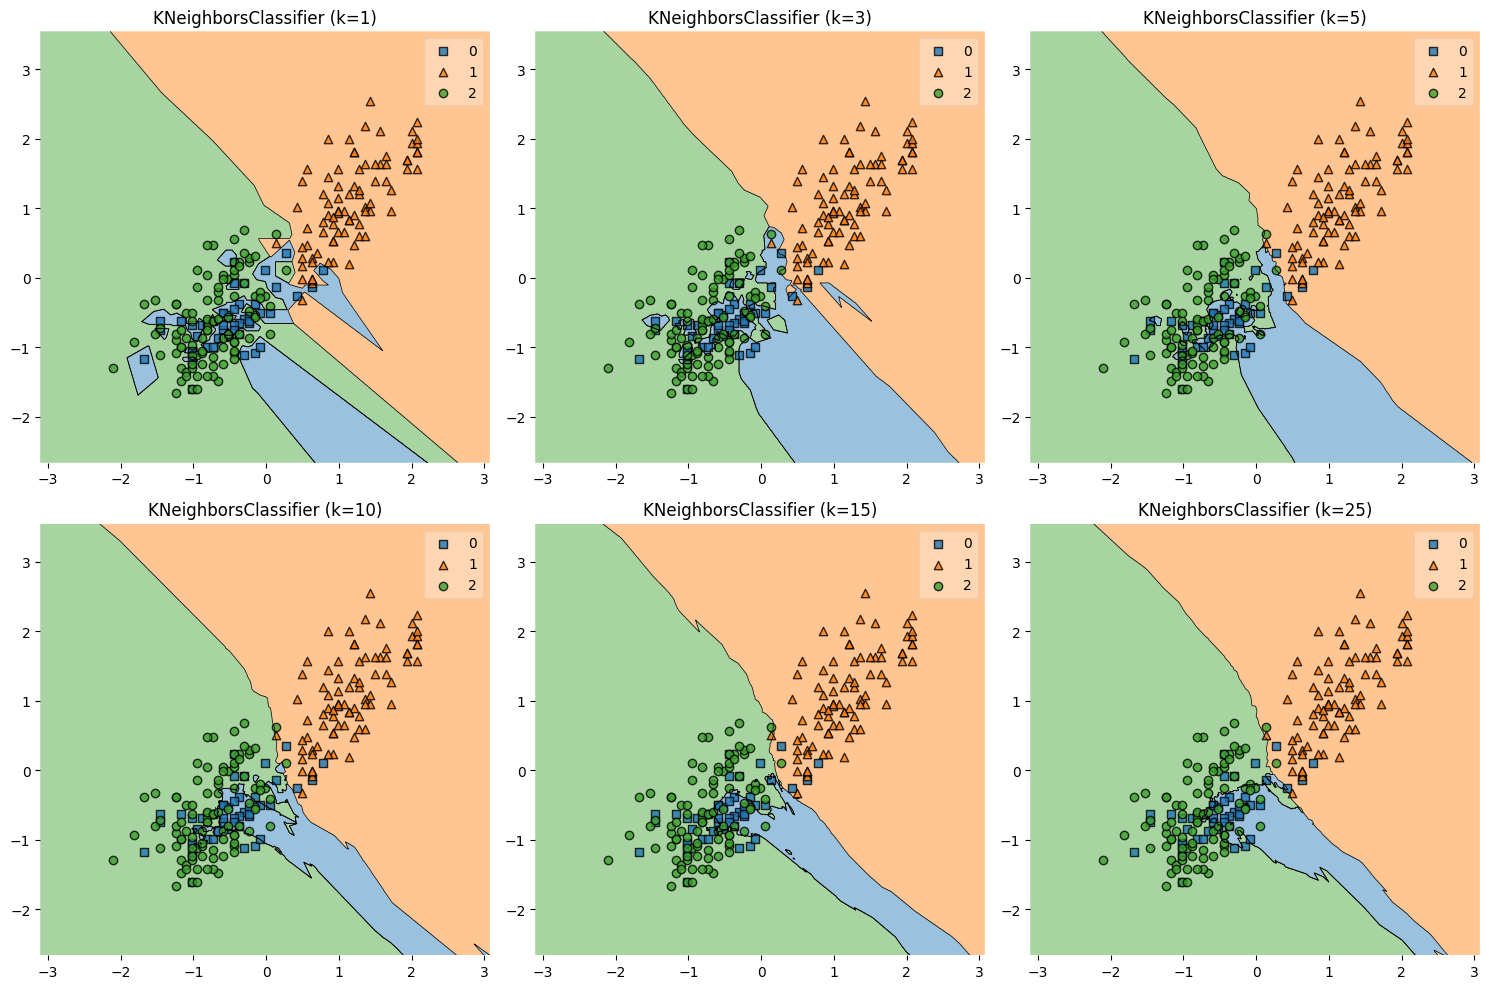

In [ ]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.gridspec as gridspec
import itertools
# будем опираться на пример 3 из документации:
gs = gridspec.GridSpec(2, 3) # создаем сетку графиков
fig = plt.figure(figsize=(15, 10))

titles = [f'KNeighborsClassifier (k=1)', 'KNeighborsClassifier (k=3)','KNeighborsClassifier (k=5)', # создаем список последовтельных заголовков графиков
          'KNeighborsClassifier (k=10)', 'KNeighborsClassifier (k=15)', 'KNeighborsClassifier (k=25)']
# возьмем полученный list_1_5 из задания 1.3:
for clf, lab, grd in zip(list_1_5, titles, itertools.product([0, 1], [0, 1, 2])): # расставляем графики по правильным местам по координатам
    ax = plt.subplot(gs[grd[0], grd[1]]) # выводим по каждой ячейке
    plot_decision_regions(X=x_train_scaled, y=y_train.values, clf=clf) # рисуем сами графики (с преобразованием y_train из pandas в numpy массив)
    ax.set_title(lab) # ставим заголовки по очереди для каждого подграфика в сетке
    ax.set_xlabel('') # убираем подпись оси Оx
    ax.set_ylabel('') # убираем подпись оси Оy

plt.tight_layout() # подгоняем графики
plt.show()

**Задача 1.6 (0.5 балла)** Прокомментируйте результаты, полученные в задачах 1.3 и 1.5. Какое число соседей оптимально использовать для обучения классификатора? Поясните ваш выбор при помощи описания геометрии данных и получаемой решающей поверхности. Какие из результатов явно говорят о переобучении модели? Почему?

**Ответ:** мы получили, что качество классификации напрямую зависит от числа соседей. При k = 1 точность на обучающей выборке очень высокая, с увеличением k она снижается, хотя на тестовой варьируется. На графике при k=1 границы классов резкие, а также образуются маленькие области вокруг отдельных точек, тк каждый объект классифицируется только по ближайшему соседу. Результаты точности при k = 1 говорят о переобучении: точность 0,97 на train и всего 0,76 на test - модель как будто просто запоминала обучающую выборку

При увеличении числа соседей решающая поверхность становится более плавной, углы сглаживаются. Например, при k = 5-15 границы уже менее фрагментированы, поскольку решение принимается по нескольким ближайшим точкам. Это уменьшает влияние случайных выбросов и делает модель более устойчивой.

При k = 25 решающая поверхность сильнее упрощает реальную структуру распределения точек. Геометрически модель очень плавно оценивает границы между кластерами. Судя по результату 1.3, k=25 является здесь оптимальным, тк дает наибольшую accuraсy для тестовой выборки.

### Задание 2. KNN своими руками. 2,5 балла

**Задача 2.1 (2 балла)** В данном задании мы попробуем реализовать алгоритм KNN своими руками, делать мы будем KNN именно для классификации.

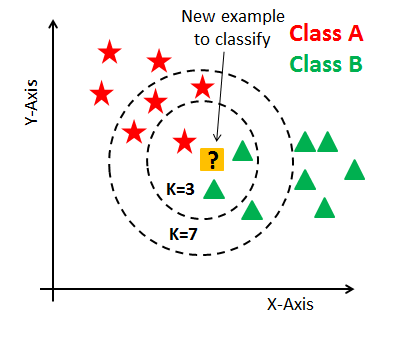

Рекомендации по реализации:
- Используйте `numpy` для представления данных в виде массивов, чтобы минимизировать преобразования.
- Избегайте циклов по всем объектам, по возможности используйте векторизированные операции.
- Обратите внимание на методы [np.linalg.norm()](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html) и [np.argsort()](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html), а также на класс `collections.Counter`.
- Особый плюс, если учтёте обработку возможных ошибок.

In [ ]:
import numpy as np
from collections import Counter

class KNN:
    def __init__(self, k:int): # сохранение значения
        self.k = k

    def fit(self, X, y): # y - класс объекта
      self.X_train = X
      self.y_train = y
      pass

    def predict(self, X):
      prediction = []
      for tests_x in X:
        dist_array = np.linalg.norm(self.X_train - tests_x, axis=1) # вычисляем расстояния от тестовой точки до всех обучающих
        distance_sorted = np.argsort(dist_array) # сортируем по расстоянию от меньшего к большему
        index_need = distance_sorted[:self.k] # берем только первые k индексов (точек с наименьшим расстояниями)
        y_need = self.y_train[index_need] # получаем значения классов, соответствующие этим индексам
        count = Counter(y_need) # считаем как часто встречается каждый класс
        prediction.append(count.most_common(1)[0][0]) # добавляем в список предсказаний наиболее популярный класс (его значение)
      return prediction
      pass

    def count_distance(self, x, y): # координаты
      distance = np.linalg.norm(x - y)
      return distance
      pass

In [ ]:
def test_knn(KNN):
  knn = KNN(k=1)
  X_train =  np.array([[1, 1], [2, 2]])
  y_train =  np.array([0, 1])
  X_test =  np.array([[1.5, 1.5]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [0]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[9.5, 9.5]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [1]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[5.5, 5.5]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [1]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[15, 15]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [1]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[5, 5], [2, 2]])
  knn.fit(X_train, y_train)
  assert all(knn.predict(X_test) == [1, 0])

**Задача 2.2 (0.5 балла)** Протестируйте ваш алгоритм на данных о пингвинах. Выведите лучший получившийся результат на тестовой выборке.

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
# аналогично заданиям 1.2-1.3:
np.random.seed(44)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

my_alg = KNN(k=3) # применим мой алгоритм при k=3
my_alg.fit(x_train_scaled, y_train.values)
y_pred = my_alg.predict(x_test_scaled)
accuracy_new = accuracy_score(y_test, y_pred) # посчитаем точность результата
print(f"Точность моего алгоритма: {round(accuracy_new, 4)}")

Точность моего алгоритма: 0.9898


### Задание 3: Линейная регрессия.

В этом задании мы рассмотрим различные аспекты построения линейной модели. Мы будем работать с одним из классических наборов данных в статистике, содержащим информацию о бриллиантах. Описание можно посмотреть [здесь](https://www.kaggle.com/shivam2503/diamonds).

In [ ]:
data = pd.read_csv('diamonds.csv')
data.head(5)

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Мы будем решать задачу предсказания цены бриллианта `price` в зависимости от его характеристик.

**Задача 3.1 (0.2 балла)** Есть ли в наборе данных пропущенные значения? Если да, удалите их.
Есть ли в наборе данных бессмысленные столбцы (признаки, не несущие дополнительной информации)? Если да, то удалите их.

In [ ]:
display(data.isnull().sum())
display(data.duplicated().sum())

,0
Unnamed: 0,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0


np.int64(0)

**Вывод:** пропущенных значений / дубликатов нет, но есть столбец с порядковым номером каждого бриллианта, что не несет нам теоретической пользы, поэтому удалим его

In [ ]:
data_clear = data.drop('Unnamed: 0', axis=1)

**Задача 3.2 (0.2 балла)** Линейная регрессия основана на предположении о линейной связи между признаками и целевой переменной, а потому перед выбором переменных для включения в модель имеет смысл проверить, насколько эта связь выполняется. Для следующих пунктов нам также потребуются выборочные корреляции между признаками. Постройте матрицу корреляций между всеми вещественными признаками и целевой переменной (то есть в этой матрице будет $k+1$ строка, где $k$ – количество вещественных признаков).

Какие вещественные признаки имеют наибольшую корреляцию с целевой переменной?

In [ ]:
data_num = data_clear.select_dtypes(include=['number']) # выбираем из нашего датафрейма только численные признаки
corr_matrix = np.round(data_num.corr(), 2) # строим корреляционную матрицу
corr_matrix_resut = corr_matrix.drop(['carat',	'depth',	'table', 'x', 'y', 'z'], axis=1) # удаляем все столбцы кроме целевой переменной для наглядности
display(corr_matrix_resut)

,price
carat,0.92
depth,-0.01
table,0.13
price,1.00
x,0.88
y,0.87
z,0.86


**Вывод:** наибольшую корреляцию с ценой имеют вес (carat = 0,92) бриллианта и его размеры (x = 0,88, y = 0,87, z = 0,86)

**Задача 3.3 (0.2 балла)** Так как линейная модель складывает значения признаков с некоторыми весами, нам нужно аккуратно обработать категориальные признаки. Закодируйте категориальные признаки методом OneHot-кодирования (`pd.get_dummies()` или `OneHotEncoder` из `sklearn`).

In [ ]:
data_categorical = data_clear.select_dtypes(include=['object']) # выбираем из нашего датафрейма только категориальные признаки
data_dum = pd.get_dummies(data_categorical, drop_first=True).astype(int) # создаем столбцы с помощью one-hot encoding
data_without_categorical = data_clear.drop(data_categorical.columns, axis=1) # удаляем столбцы с категориальными данными
data_clear = pd.concat([data_without_categorical, data_dum], axis=1) # склеиваем в единый датафрейм
# для задания 3.6:
common_columns = ['carat',	'depth', 'table',	'price', 'x',	'y', 'z'] # наши изначальные колонки (числовые)
one_hot_columns = data_dum.columns.tolist() # все колонки one-hot
display(data_clear.head())

,carat,depth,table,price,x,y,z,cut_Good,cut_Ideal,cut_Premium,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,0,1,0,...,0,0,0,0,0,1,0,0,0,0
1,0.21,59.8,61.0,326,3.89,3.84,2.31,0,0,1,...,0,0,0,0,1,0,0,0,0,0
2,0.23,56.9,65.0,327,4.05,4.07,2.31,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0.29,62.4,58.0,334,4.20,4.23,2.63,0,0,1,...,0,1,0,0,0,0,0,1,0,0
4,0.31,63.3,58.0,335,4.34,4.35,2.75,1,0,0,...,0,0,1,0,0,1,0,0,0,0


**Задача 3.4 (0.2 балла)** Разделите выборку на тренировочную и тестовую. Долю тестовой выборки укажите равной 0.3.

In [ ]:
from sklearn.model_selection import train_test_split
y = data_clear['price'] # целевая переменная
x = data_clear.drop('price', axis=1) # признаки (все кроме целевой переменной)
np.random.seed(42)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3) # разделение выборки

**Задача 3.5 (0.3 балла)** Зачастую при использовании линейных моделей вещественные признаки масштабируются. При этом оценки коэффициентов теряют прямую статистическую интерпретацию ("при увеличении $X_1$ на 1, $y$ увеличивается на $w_1$"), но приобретают свойства, полезные в задачах машинного обучения. В этой задаче стандартизируйте вещественные признаки в тренировочной и тестовой выборках с помощью `StandardScaler`.

Объясните, как это повлияет на интерпретацию коэффициентов линейной регрессии.

In [ ]:
from sklearn.preprocessing import StandardScaler
x_train_3_5 = x_train[['carat',	'depth',	'table',	'x',	'y',	'z']] # выберем только числовые признаки для train
x_test_3_5 = x_test[['carat',	'depth',	'table',	'x',	'y',	'z']] # аналогично и для test
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_3_5) # модель обучается на train
x_test_scaled = scaler.transform(x_test_3_5) # модель применяет те же параметры на test

# преобразуем из numpy array в DataFrame:
x_train_df = pd.DataFrame(x_train_scaled, columns=['carat', 'depth', 'table', 'x', 'y', 'z'], index=x_train.index) # для train
x_test_df = pd.DataFrame(x_test_scaled, columns=['carat', 'depth', 'table', 'x', 'y', 'z'], index=x_test.index) # для test
# объединим стандартизированные признаки с полученными ранее one-hot столбцами (для задания 3.6):
x_train_res = pd.concat([x_train_df, x_train[one_hot_columns]], axis=1) # для train
x_test_res = pd.concat([x_test_df, x_test[one_hot_columns]], axis=1) # для test

**Ответ:** после стандартизации признаки имеют нулевое среднее и единичную дисперсию, поэтому коэффициенты линейной регрессии показывают изменение целевой переменной при изменении признака на одно стандартное отклонение, а не на одну исходную единицу измерения, что можно интерпретировать, в отличие от исходного варианта

**Задача 3.6 (0.2 балла)** Оцените линейную регрессию на тренировочной выборке. Выведите среднеквадратичную ошибку на тренировочной и тестовой выборках.

In [ ]:
from sklearn.linear_model import LinearRegression

def MSE(y: np.array, y_pred: np.array) -> np.float64: # функция MSE с семинара
  return ((y - y_pred) ** 2).mean()

model = LinearRegression()
model.fit(x_train_res, y_train)  # обучаем модель на данных train

# делаем предсказание
y_train_pred = model.predict(x_train_res) # для train
y_test_pred = model.predict(x_test_res) # для test

# применяем функцию (поиск среднеквадратичной ошибки)
mse_train = MSE(y=y_train, y_pred=y_train_pred)
mse_test = MSE(y=y_test, y_pred=y_test_pred)

print(f'MSE на train: {mse_train}')
print(f'MSE на test: {mse_test}')

MSE на train: 1290541.9147450614
MSE на test: 1244765.4357158695


**Задача 3.7 (0.3 балла)** Изучите [документацию](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) модуля `LinearRegression` и выведите полученные оценки коэффициентов. Назовите вещественные переменные, оценки коэффициентов которых по модулю на порядок превышают оценки прочих вещественных переменных.

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(x_train_res, y_train) # смотрим только на вещественные признаки
coef = lin_reg.coef_ # массив коэффициентов
coef_sorted_3_7 = pd.DataFrame({'Признак': x_train_res.columns,'Коэффициент': coef}) # создаем датафрейм и берем модуль
coef_sorted_3_7 = coef_sorted_3_7.sort_values('Коэффициент', key=abs, ascending=False) # сортируем от большего к меньшему
display(coef_sorted_3_7)

,Признак,Коэффициент
16,clarity_IF,5459.037300
0,carat,5338.615671
21,clarity_VVS1,5101.335181
22,clarity_VVS2,5028.295530
19,clarity_VS1,4657.834307
20,clarity_VS2,4336.725583
17,clarity_SI1,3751.709671
18,clarity_SI2,2781.940548
15,color_J,-2381.989788
14,color_I,-1476.084233


**Вывод:** наибольшие коэффициенты (по модулю) у переменных clarity (от 2781 до 5459) и carat (≈5338). Так, вес бриллианта и его чистота наиболее сильно влияют на его цену.

**Задача 3.8 (0.5 балла)** Как можно заметить из анализа корреляционной матрицы в задаче 3.3, между некоторыми признаками имеется сильная корреляция, что может быть индикатором проблемы *мультиколлинеарности*. Различия в порядке коэффициентов, выявленные в предыдущей задаче также намекают на её присутствие. Как известно, для решения этой проблемы можно либо исключить некоторые признаки из модели, либо использовать регуляризацию. Мы воспользуемся вторым вариантом.

Вспомним, что смысл регуляризации заключается в том, чтобы изменить функцию потерь так, чтобы устранить проблемы, появляющиеся из-за мультиколлинеарности. При L1-регуляризации предлагается минимизировать следующую функцию потерь:

$$
\|y - X\hat{w}\|^2 + \alpha\sum_{i=1}^k|w_i|
$$

Такая модель называется Lasso-регрессией.

При L2-регуляризации предлагается минимизировать следующую функцию потерь:

$$
\|y - X\hat{w}\|^2 + \alpha\|w\|^2
$$

Такая модель называется Ridge-регрессией.

Обучите Lasso-регрессию и Ridge-регрессию, установив гиперпараметр регуляризации равным 10. Для этого используйте модули `Lasso` и `Ridge` из `sklearn`. Сильно ли уменьшились веса? Сделайте вывод о том, насколько сильно проблема мультиколлинеарности проявлялась в изначальной регрессии.

In [ ]:
from sklearn import linear_model
from sklearn.linear_model import Ridge
np.set_printoptions(suppress=True) # чтобы числа выводились в массиве в обычном виде (а то выводится с e)
# для lasso:
clf_lasso = linear_model.Lasso(alpha=10)
clf_lasso.fit(x_train_res, y_train) # смотрим только на вещественные признаки
coef_clf_lasso = clf_lasso.coef_ # массив коэффициентов
# аналогично для ridge:
clf_ridge = Ridge(alpha=10)
clf_ridge.fit(x_train_res, y_train)
coef_clf_ridge = clf_ridge.coef_
# выведем таблицы для наглядности
coef_lasso_df = pd.DataFrame({'Признак': x_train_res.columns,'Коэффициенты Lasso': clf_lasso.coef_}) # для lasso
coef_lasso_df = coef_lasso_df.sort_values('Коэффициенты Lasso', key=abs, ascending=False)
display(coef_lasso_df)
print('')
coef_ridge_df = pd.DataFrame({'Признак': x_train_res.columns,'Коэффициенты Ridge': clf_ridge.coef_ }) # для ridge
coef_ridge_df = coef_ridge_df.sort_values('Коэффициенты Ridge', key=abs, ascending=False)
display(coef_ridge_df)

,Признак,Коэффициенты Lasso
0,carat,4756.602190
15,color_J,-1789.095818
16,clarity_IF,1338.757825
21,clarity_VVS1,1171.119809
22,clarity_VVS2,1160.848739
14,color_I,-995.890457
19,clarity_VS1,821.889605
18,clarity_SI2,-803.616312
3,x,-681.275333
13,color_H,-608.555564


,Признак,Коэффициенты Ridge
0,carat,5286.285876
16,clarity_IF,4854.461972
21,clarity_VVS1,4520.016166
22,clarity_VVS2,4454.315818
19,clarity_VS1,4090.432704
20,clarity_VS2,3775.032112
17,clarity_SI1,3193.741711
15,color_J,-2345.505217
18,clarity_SI2,2231.686572
14,color_I,-1450.008214


**Вывод:** коэффициенты немного уменьшились по сравнению с обычной линейной регрессией. В Ridge-регрессии коэффициенты уменьшились не так сильно, как в Lasso, но при этом все остались ненулевыми. В Lasso-регрессии некоторые коэффициенты занулились (y, cut_Good, color_F и color_E) или стали близки к нулю (clarity_SI1, z). При этом самые большие коэффициенты (carat и лучшие clarity) остались так же высоко. Это говорит о том, что мультиколлинеарность в исходной модели присутствует (например, между carat, x, y, z), но она не очень сильна

**Задача 3.9 (0.5 балла)** Как обсуждалось на семинарах, Lasso-регрессию можно использовать для отбора наиболее информативных признаков. Для следующих значений параметра регуляриазции $\alpha$: 0.1, 1, 10, 100, 200 –  обучите Lasso- и Ridge-регрессии и постройте график изменения евклидовой нормы весов (`np.linalg.norm()` от вектора оценок коэффициентов) в зависимости от параметра $\alpha$. Как известно, норма является численной характеристикой величины вектора, а потому по норме можно судить о том, насколько большие элементы содержит вектор оценок коэффициентов.

Какой метод сильнее снижает норму коэффициентов? Поясните, почему Lasso-регрессию часто используют для отбора признаков.

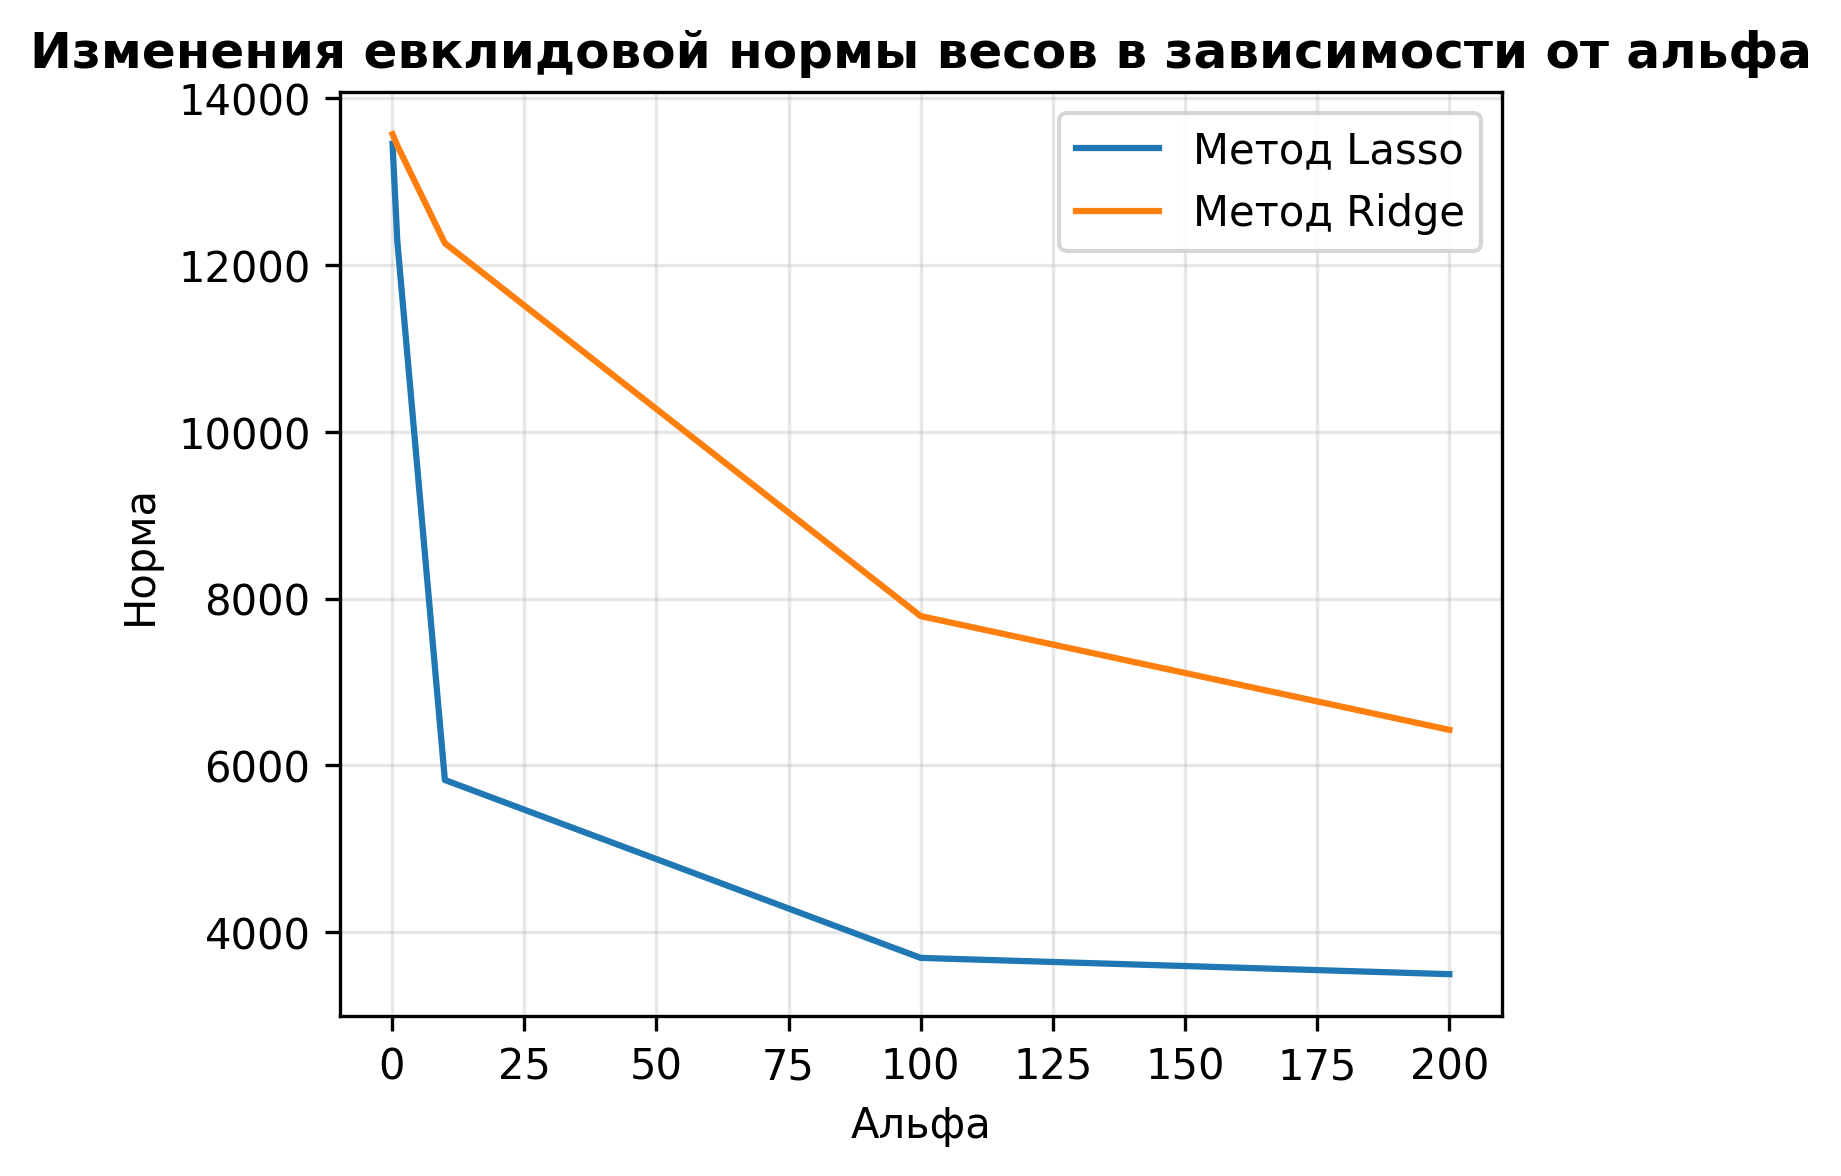

In [ ]:
a_list = [0.1, 1, 10, 100, 200] # список необходимых для рассмотрения значений альфа (из условия)
lasso_norms = []
ridge_norms = []

def lasso_reg(a, x_train_res, y_train):
  clf_lasso = linear_model.Lasso(alpha=a)
  clf_lasso.fit(x_train_res, y_train)
  return clf_lasso.coef_ # массив коэффициентов

def ridge_reg(a, x_train_res, y_train):
  clf_ridge = Ridge(alpha=a)
  clf_ridge.fit(x_train_res, y_train)
  return clf_ridge.coef_ # массив коэффициентов

for a in a_list: # для каждого из списка значений альфы выполняем функцию
  massiv_lasso = np.array(lasso_reg(a, x_train_res, y_train))
  lasso_norms.append(np.linalg.norm(massiv_lasso))
  massiv_ridge = np.array(ridge_reg(a, x_train_res, y_train))
  ridge_norms.append(np.linalg.norm(massiv_ridge))

# строим график:
plt.figure(figsize=(5, 4), dpi=300)
plt.plot(a_list, lasso_norms, label='Метод Lasso')
plt.plot(a_list, ridge_norms, label='Метод Ridge')
plt.title('Изменения евклидовой нормы весов в зависимости от альфа', fontweight='bold')
plt.xlabel('Альфа')
plt.ylabel('Норма')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Вывод:** при увеличении альфа Lasso снижает норму коэффициентов значительно быстрее, чем Ridge.
Это можно объяснить разным типом используемой регулязации: у Lasso L1, где штраф пропорционален сумме модулей коэффициентов. Это приводит к занулению коэффициентов неважных признаков. У Ridge L2, где штраф пропорционален сумме квадратов коэффициентов. Так, коэффициенты уменьшаются, но не достигают 0, следовательно, все признаки остаются в модели, просто с меньшими весами

Lasso-регрессию используют именно для отбора признаков, тк когда неинформативным признакам зануляют коэффициенты, они перестают влиять на модель, что позволяет упростить ее, как раз отобрав нужные признаки.

**Задача 3.10 (0.5 балла)**
В зависимости от значения параметра $\alpha$ в Lasso-регрессии зануляются разные оценки коэффициентов. Оптимальное значение $\alpha$ можно подобрать, например, при помощи кросс-валидации по тренировочной выборке.

Для проведения кросс-валидации можно использовать модуль `LassoCV`. Этот модуль принимает список значений $\alpha$ (параметр `alphas`) и при обучении проводит кросс-валидацию для каждого значения из этого списка, сохраняя MSE на каждом участке кросс-валидации (количество участков – параметр `cv`) в матрицу ошибок (то есть итоговая матрица будет иметь размер `len(alphas)` $\times$ `cv`). После обучения модели матрицу ошибок можно получить, обратившись к атрибуту `.mse_path_`.

Заметим, что модель может использовать $\alpha$ не в том порядке, в котором вы подаёте их в функцию: для определения порядка используйте атрибут `.alphas_` Установите количество участков для кросс-валидации (параметр `cv`) равным 5.

Усредните ошибки для каждого значения $\alpha$ (то есть по строкам матрицы ошибок) и выберите то значение, которое даёт наибольшее качество.

In [ ]:
from sklearn.linear_model import LassoCV
a_list = [0.1, 1, 10, 100, 200] # список альфа из предыдущего задания
reg_lassoCV = LassoCV(cv=5, alphas=a_list, max_iter=100000,).fit(x_train_res, y_train) # сама модель
matrix = reg_lassoCV.mse_path_ # получим матрицу ошибок
mean_mse = np.mean(matrix, axis=1) # устредняем матрицу по строкам
a_need = reg_lassoCV.alphas_[np.argmin(mean_mse)] # сохранение альфа, при которой ошибка минимальна
mse_min = mean_mse[np.argmin(mean_mse)] # вывод наименьшей ошибки через ее индекс
print(f'Наименьшая ошибка = {mse_min} достигается при a = {a_need}')

Наименьшая ошибка = 1295967.7628991217 достигается при a = 0.1


**Задача 3.11 (0.5 балла)** Обучите итоговую Lasso-регрессию с выбранным параметром $\alpha$ на тренировочной выборке. Выведите полученные коэффициенты и прокомментируйте, какие признаки оказались неинформативными, а какие – наиболее информативными. Приведите возможное смысловое объяснение этого результата.

In [ ]:
clf_lasso_new = linear_model.Lasso(alpha=0.1)
clf_lasso_new.fit(x_train_res, y_train)
coef_clf_lasso_new = clf_lasso_new.coef_ # массив коэффициентов
# выведем таблицу с отсортированными по модулю коэффициентами
coef_sorted = pd.DataFrame({'Признак': x_train_res.columns,'Коэффициент': abs(clf_lasso_new.coef_)}) # создаем датафрейм и берем модуль
coef_sorted = coef_sorted.sort_values('Коэффициент', ascending=False) # сортируем от большего к меньшему
display(coef_sorted)

,Признак,Коэффициент
16,clarity_IF,5402.396479
0,carat,5332.422145
21,clarity_VVS1,5046.644984
22,clarity_VVS2,4974.320848
19,clarity_VS1,4604.228786
20,clarity_VS2,4283.913095
17,clarity_SI1,3699.213091
18,clarity_SI2,2729.882663
15,color_J,2373.827973
14,color_I,1469.034296


**Вывод:** наиболее информативными оказались признаки степени чистоты (clarity) и вес бриллианта (carat), наименее информативными - размеры (y, z) и пропорции (depth, table). Так, чистота напрямую определяет качество бриллианта: чем меньше дефектов, тем выше будет цена, таким образом, наибольшие коэффициенты у лучших степеней чистоты (IF, VVS1, VVS2). ес же является чуть ли главным фактором, напрямую определяющим стоимость бриллианта. Признаки ширины верхней части бриллианта, ширины y и глубины z сильно коррелируют с весом (carat) и длиной x, поэтому модель уменьшает их коэффициенты

**Задача 3.12 (0.4 балла)** Сделайте предсказания обученной Lasso-регрессии на тестовой выборке и сравните среднеквадратичную ошибку с ошибкой обычной линейной регрессии из задачи 3.7. Какую модель лучше использовать для предсказаний? Приведите возможное объяснение, почему одна модель оказалась лучше другой.

In [ ]:
from sklearn.metrics import mean_squared_error
clf_lasso_new = linear_model.Lasso(alpha=0.1) # из предыдущего номера
clf_lasso_new.fit(x_train_res, y_train)
y_test_pred_lasso = clf_lasso_new.predict(x_test_res) # предсказание для test lasso
mse_lasso = mean_squared_error(y_test, y_test_pred_lasso) # mse для lasso
# из номера 3.7:
lin_reg = LinearRegression()
lin_reg.fit(x_train_res, y_train)
y_test_pred_lin = lin_reg.predict(x_test_res) # предсказание для test lin reg
mse_linear = mean_squared_error(y_test, y_test_pred_lin) # mse для lin reg
print(f' Ошибка по lasso-регрессии={mse_lasso}, по линейной регрессии={mse_linear}')

 Ошибка по lasso-регрессии=1244336.150823827, по линейной регрессии=1244765.4357158695


**Вывод:** по Лассо-регрессии ошибка получилась немного меньше. Эта модель оказалась лучше, потому что она уменьшила коэффициенты менее важных и коррелированных признаков (например, y и z), устранив мультиколлинеарность. Линейная регрессия не использует регуляризацию, поэтому её коэффициенты могут меняться, что приводит к большей ошибке